# AfriMarket — Analyse stratégique de l'activité e-commerce (juil.–déc. 2025)

**Auteur :** Data Analyst · **Données :** `data/afrimarket_dataset_senior.csv` (6 mois, 10 100 lignes brutes)

**Questions de la direction :** pourquoi le CA fluctue-t-il, où part l'argent marketing, quelles catégories et villes
créent (ou détruisent) de la valeur, et que faire concrètement ?

**Plan du notebook**
1. Audit et compréhension des données
2. Data cleaning → `df_clean`
3. Feature engineering (et hypothèses comptables)
4. Analyses : globale, catégories, géographie, marketing, clients
5. Cinq recommandations stratégiques
6. Conclusion orientée action

> **Convention :** les montants sont exprimés dans la devise du dataset (non précisée), notée *UM*.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype"
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import afrimarket_utils as u          # règles de nettoyage partagées avec le dashboard
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

def fmt(x): return f"{x:,.0f}".replace(",", " ")
def save(name): plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Audit & compréhension des données

In [2]:
df_raw = u.load_raw()
print(f"Dimensions : {df_raw.shape[0]:,} lignes × {df_raw.shape[1]} colonnes".replace(",", " "))
df_raw.head()

Dimensions : 10 100 lignes × 14 colonnes


,id_commande,date_commande,id_client,ville,categorie,nom_produit,prix_unitaire,quantite,remise,cout_livraison,methode_paiement,canal_marketing,cout_marketing,statut_commande
0,CMD100000,2025-12-11,C0379,Brazzaville,Mode,Produit_Mode_9,49.72,3,0.07,2.45,Mobile Money,Email,1.00,Livrée
1,CMD100001,2025-07-27,C1827,Libreville,Beauté,Produit_Beauté_3,37.18,2,0.10,6.89,Paiement à la livraison,Instagram Ads,8.04,Livrée
2,CMD100002,2025-07-08,C0119,Abidjan,electronique,Produit_Électronique_36,315.60,0,0.04,5.60,Carte,Google Ads,7.30,Livrée
3,CMD100003,2025-08-20,C1436,Libreville,electronique,Produit_Électronique_29,143.25,0,0.03,5.96,Mobile Money,Google Ads,5.20,Livrée
4,CMD100004,2025-11-28,C0003,Libreville,Électronique,Produit_Électronique_45,498.71,2,0.02,5.16,Mobile Money,Email,0.55,Livrée


In [3]:
# Structure et types
pd.DataFrame({"type": df_raw.dtypes.astype(str), "manquants": df_raw.isna().sum(),
              "valeurs_uniques": df_raw.nunique()})

,type,manquants,valeurs_uniques
id_commande,str,0,10000
date_commande,str,0,184
id_client,str,0,1772
ville,str,0,9
categorie,str,0,5
nom_produit,str,0,200
prix_unitaire,float64,0,7432
quantite,int64,0,4
remise,float64,0,32
cout_livraison,float64,0,801


In [4]:
# Statistiques descriptives des variables numériques
df_raw[["prix_unitaire", "quantite", "remise", "cout_livraison", "cout_marketing"]].describe().T

,count,mean,std,min,25%,50%,75%,max
prix_unitaire,"10,100.00",140.49,172.03,-50.00,28.06,52.97,201.88,915.86
quantite,"10,100.00",1.87,0.92,0.00,1.00,2.00,3.00,3.00
remise,"10,100.00",0.11,0.10,-0.10,0.05,0.09,0.19,0.30
cout_livraison,"10,100.00",6.01,2.30,2.00,4.04,5.99,8.03,10.00
cout_marketing,"10,100.00",7.39,4.64,0.50,3.98,6.87,10.85,19.98


In [5]:
# Synthèse d'audit : chaque problème de qualité détecté et son volume
a = u.audit(df_raw)
audit_df = pd.DataFrame({
    "Problème détecté": ["Valeurs manquantes", "Doublons exacts (même id_commande)", "Prix ≤ 0 (valeur sentinelle -50)",
                         "Quantités nulles", "Remises négatives", "Villes mal orthographiées (« Kinshassa »)",
                         "Catégories non standard (« electronique »)", "Statuts non standard (« retournée » en minuscule)"],
    "Lignes concernées": [a["valeurs_manquantes"], a["doublons_exacts"], a["prix_negatifs_ou_nuls"],
                          a["quantites_nulles"], a["remises_negatives"], a["villes_mal_orthographiees"],
                          a["categories_non_standard"], a["statuts_non_standard"]]})
audit_df["% du fichier"] = (audit_df["Lignes concernées"] / len(df_raw) * 100).round(1)
audit_df

,Problème détecté,Lignes concernées,% du fichier
0,Valeurs manquantes,0,0.00
1,Doublons exacts (même id_commande),100,1.00
2,Prix ≤ 0 (valeur sentinelle -50),632,6.30
3,Quantités nulles,608,6.00
4,Remises négatives,614,6.10
5,Villes mal orthographiées (« Kinshassa »),605,6.00
6,Catégories non standard (« electronique »),606,6.00
7,Statuts non standard (« retournée » en minuscule),826,8.20


In [6]:
# Détail des incohérences de libellés
for c in ["ville", "categorie", "statut_commande"]:
    print(df_raw[c].value_counts().to_string(), "\n")
print("Période :", df_raw.date_commande.min(), "→", df_raw.date_commande.max(), "(format ISO homogène)")
print("Coûts marketing stockés comme texte à zéro initial (ex. « 08.04 ») : lus correctement en numérique.")

ville
Kinshasa       2349
Abidjan        1886
Douala         1449
Dakar          1434
Lomé            735
Cotonou         677
Kinshassa       605
Libreville      493
Brazzaville     472 

categorie
Mode            3005
Électronique    2638
Maison          1948
Beauté          1903
electronique     606 

statut_commande
Livrée       9080
retournée     826
Annulée       194 

Période : 2025-07-01 → 2025-12-31 (format ISO homogène)
Coûts marketing stockés comme texte à zéro initial (ex. « 08.04 ») : lus correctement en numérique.


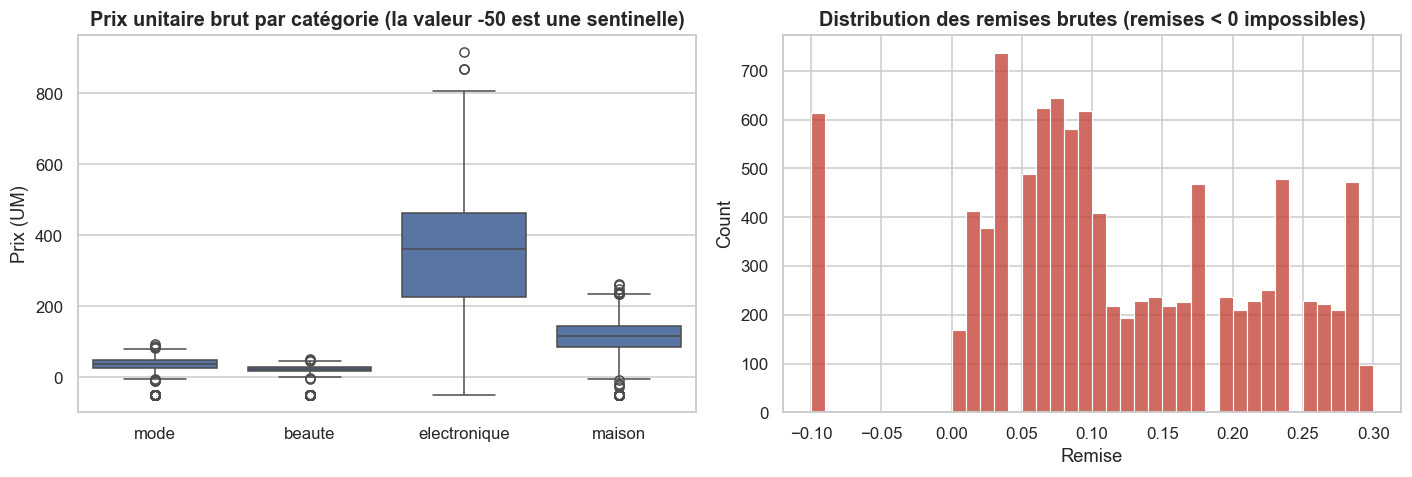

In [7]:
# Valeurs aberrantes : prix par catégorie (avant nettoyage)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df_raw.assign(cat=df_raw.categorie.str.lower().str.replace("é", "e")), x="cat", y="prix_unitaire", ax=ax[0])
ax[0].set_title("Prix unitaire brut par catégorie (la valeur -50 est une sentinelle)"); ax[0].set_xlabel(""); ax[0].set_ylabel("Prix (UM)")
sns.histplot(df_raw.remise, bins=40, ax=ax[1], color="#c0392b")
ax[1].set_title("Distribution des remises brutes (remises < 0 impossibles)"); ax[1].set_xlabel("Remise")
plt.tight_layout(); save("01_audit_aberrations"); plt.show()

### Résumé de l'audit
Le fichier ne contient **aucune valeur manquante** et un format de date homogène, mais **six familles de défauts** :
- **100 doublons exacts** (lignes recopiées en fin de fichier) ;
- **632 prix à −50** : valeur sentinelle impossible, répartie sur toutes les catégories et tous les produits ;
- **608 quantités nulles** (commande sans article) et **614 remises négatives** (impossible : une remise ne peut pas augmenter le prix) ;
- **605 villes « Kinshassa »** à fusionner avec Kinshasa, **606 catégories « electronique »** sans accent/majuscule, et statuts « retournée » en minuscule.

La structure est par ailleurs saine : 8 villes, 4 catégories, 200 produits, 4 canaux, 1 772 clients identifiés (id valides à 100 %).
Les prix valides sont cohérents au sein de chaque catégorie (pas de valeur extrême haute au sens IQR×3 après traitement du −50).

## 2. Data cleaning → `df_clean`

| Problème | Traitement | Justification |
|---|---|---|
| Dates | conversion en `datetime` | permet les analyses mensuelles |
| Catégories / villes / statuts | normalisation de la casse, accents et fautes | éviter de scinder une même entité |
| Doublons | suppression (ligne exacte + `id_commande`) | évite de compter deux fois le CA |
| Remises négatives | ramenées à 0 | une remise ne peut pas majorer un prix ; on conserve la commande |
| Prix −50 | imputés par la **médiane du produit** (sinon de la catégorie) | conserve la commande avec un prix réaliste, sans biais de catégorie |
| Prix extrêmes hauts | plafonnement IQR×3 par catégorie | garde-fou (aucun cas détecté ici) |
| Quantités nulles | **lignes supprimées** | une commande sans article n'a ni CA ni logique métier |

In [8]:
df_clean, log = u.clean(df_raw, return_log=True)
pd.Series(log, name="nombre").to_frame()

,nombre
dates_invalides,0
doublons_supprimes,100
remises_negatives_corrigees,600
prix_invalides_imputes,622
prix_extremes_plafonnes,0
quantites_nulles_supprimees,600


In [9]:
# Contrôle qualité après nettoyage
checks = {
    "lignes avant → après": f"{len(df_raw):,} → {len(df_clean):,}".replace(",", " "),
    "doublons restants": int(df_clean.id_commande.duplicated().sum()),
    "prix ≤ 0": int((df_clean.prix_unitaire <= 0).sum()),
    "quantités ≤ 0": int((df_clean.quantite <= 0).sum()),
    "remises < 0": int((df_clean.remise < 0).sum()),
    "villes": sorted(df_clean.ville.unique()),
    "catégories": sorted(df_clean.categorie.unique()),
    "statuts": sorted(df_clean.statut_commande.unique()),
}
pd.Series(checks, name="contrôle").to_frame()

,contrôle
lignes avant → après,10 100 → 9 400
doublons restants,0
prix ≤ 0,0
quantités ≤ 0,0
remises < 0,0
villes,"[Abidjan, Brazzaville, Cotonou, Dakar, Douala,..."
catégories,"[Beauté, Maison, Mode, Électronique]"
statuts,"[Annulée, Livrée, Retournée]"


## 3. Feature engineering

Le dataset ne fournit pas les coûts d'achat : la **marge brute est donc estimée** avec un taux de coût des marchandises par catégorie
(**hypothèse à valider avec la finance**) : Électronique 75 %, Maison 60 %, Mode 50 %, Beauté 40 %.

**Règles comptables retenues**
- `chiffre_affaires` = prix × quantité × (1 − remise), **uniquement pour les commandes Livrées** (annulées et retournées ne rapportent rien) ;
- `marge_brute` = CA × (1 − taux de coût de la catégorie) ;
- `profit_net` = marge brute − livraison supportée − coût marketing. La livraison est supportée pour les commandes Livrées **et Retournées** (aller-retour perdu), pas pour les Annulées ; le marketing est dépensé quelle que soit l'issue ;
- `valeur_vie_client` (CLV simplifiée) = profit net cumulé du client sur la période observée.

In [10]:
cols = ["id_commande", "mois_label", "categorie", "ville", "statut_commande", "chiffre_affaires", "marge_brute",
        "profit_net", "indicateur_retour", "nombre_commandes_par_client", "valeur_vie_client"]
df_clean[cols].head(8)

,id_commande,mois_label,categorie,ville,statut_commande,chiffre_affaires,marge_brute,profit_net,indicateur_retour,nombre_commandes_par_client,valeur_vie_client
0,CMD100000,2025-12,Mode,Brazzaville,Livrée,138.72,69.36,65.91,0,25,"1,972.76"
1,CMD100001,2025-07,Beauté,Libreville,Livrée,66.92,40.15,25.22,0,4,139.69
2,CMD100004,2025-11,Électronique,Libreville,Livrée,977.47,244.37,238.66,0,26,"1,555.29"
3,CMD100005,2025-10,Maison,Dakar,Livrée,192.16,76.86,62.78,0,17,"1,205.97"
4,CMD100006,2025-07,Mode,Abidjan,Livrée,69.12,34.56,21.74,0,16,640.43
5,CMD100007,2025-10,Beauté,Lomé,Livrée,67.29,40.37,31.70,0,21,"1,484.90"
6,CMD100008,2025-12,Mode,Abidjan,Livrée,133.08,66.54,60.72,0,3,183.80
7,CMD100009,2025-12,Électronique,Dakar,Livrée,"1,035.46",258.87,244.30,0,19,732.19


## 4. Analyses

### 4.1 Performance globale

In [11]:
livrees = df_clean[df_clean.statut_commande == "Livrée"]
kpi = pd.Series({
    "CA total (UM)": df_clean.chiffre_affaires.sum(),
    "Profit net estimé (UM)": df_clean.profit_net.sum(),
    "Marge nette (% du CA)": df_clean.profit_net.sum() / df_clean.chiffre_affaires.sum() * 100,
    "Panier moyen – commandes livrées (UM)": livrees.montant_brut.mean(),
    "Taux d'annulation (%)": df_clean.indicateur_annulation.mean() * 100,
    "Taux de retour (%)": df_clean.indicateur_retour.mean() * 100,
    "Nombre de commandes": len(df_clean),
}, name="valeur").to_frame()
kpi

,valeur
CA total (UM),"2,196,631.17"
Profit net estimé (UM),"547,383.60"
Marge nette (% du CA),24.92
Panier moyen – commandes livrées (UM),259.89
Taux d'annulation (%),1.95
Taux de retour (%),8.14
Nombre de commandes,"9,400.00"


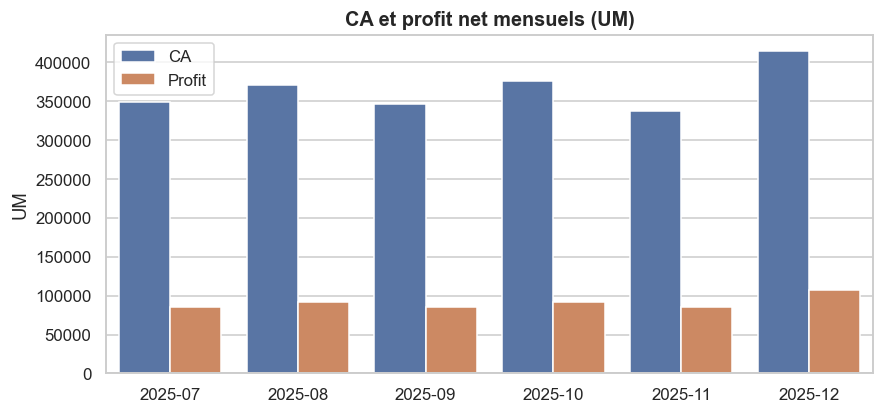

,mois_label,CA,Profit,commandes,croissance_CA_%
0,2025-07,"349,412.07","85,919.15",1513,NaN
1,2025-08,"371,020.54","91,929.68",1579,6.18
2,2025-09,"346,677.97","85,061.16",1468,-6.56
3,2025-10,"376,579.13","91,572.79",1617,8.63
4,2025-11,"338,097.92","86,048.19",1524,-10.22
5,2025-12,"414,843.55","106,852.64",1699,22.70


In [12]:
mensuel = df_clean.groupby("mois_label").agg(CA=("chiffre_affaires", "sum"), Profit=("profit_net", "sum"),
                                              commandes=("id_commande", "count")).reset_index()
mensuel["croissance_CA_%"] = mensuel.CA.pct_change() * 100
fig = px.bar(mensuel, x="mois_label", y=["CA", "Profit"], barmode="group", title="CA et profit net par mois (UM)",
             labels={"value": "UM", "mois_label": "Mois", "variable": ""})
fig.show()
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=mensuel.melt("mois_label", ["CA", "Profit"]), x="mois_label", y="value", hue="variable", ax=ax)
ax.set_title("CA et profit net mensuels (UM)"); ax.set_xlabel(""); ax.set_ylabel("UM"); ax.legend(title="")
save("02_mensuel"); plt.show()
mensuel

**Lecture.** Sur 6 mois, AfriMarket réalise **2 196 631 UM de CA** et **547 384 UM de profit net estimé**
(marge nette 24,9 %), avec un panier moyen de **260 UM**. L'annulation est faible (1,9 %)
mais le **taux de retour de 8,1 %** est le vrai point de fuite : un retour supprime le revenu tout en laissant
les frais de livraison et de marketing. Les variations du CA mensuel (creux en novembre, pic en décembre) sont **d'abord un effet de volume
de commandes**, pas de panier : le volume suit la saisonnalité, ce qui incite à planifier stocks et budget en amont.

### 4.2 Analyse par catégorie

In [13]:
cat = df_clean.groupby("categorie").agg(
    commandes=("id_commande", "count"), CA=("chiffre_affaires", "sum"), marge_brute=("marge_brute", "sum"),
    profit_net=("profit_net", "sum"), cout_marketing=("cout_marketing", "sum"), taux_retour=("indicateur_retour", "mean"))
cat["taux_marge_brute_%"] = cat.marge_brute / cat.CA * 100
cat["profit_par_commande"] = cat.profit_net / cat.commandes
cat["marketing_en_%_du_CA"] = cat.cout_marketing / cat.CA * 100
cat["taux_retour"] *= 100
cat["part_du_CA_%"] = cat.CA / cat.CA.sum() * 100
cat = cat.sort_values("CA", ascending=False)
cat

,commandes,CA,marge_brute,profit_net,cout_marketing,taux_retour,taux_marge_brute_%,profit_par_commande,marketing_en_%_du_CA,part_du_CA_%
categorie,,,,,,,,,,
Électronique,3006,"1,591,064.21","397,766.05","357,954.05","22,173.79",13.84,25.00,119.08,1.39,72.43
Maison,1799,"357,708.28","143,083.31","119,260.80","13,183.23",4.95,40.00,66.29,3.69,16.28
Mode,2837,"173,059.44","86,529.72","48,893.82","21,036.29",7.44,50.00,17.23,12.16,7.88
Beauté,1758,"74,799.24","44,879.54","21,274.92","13,111.43",2.79,60.00,12.10,17.53,3.41


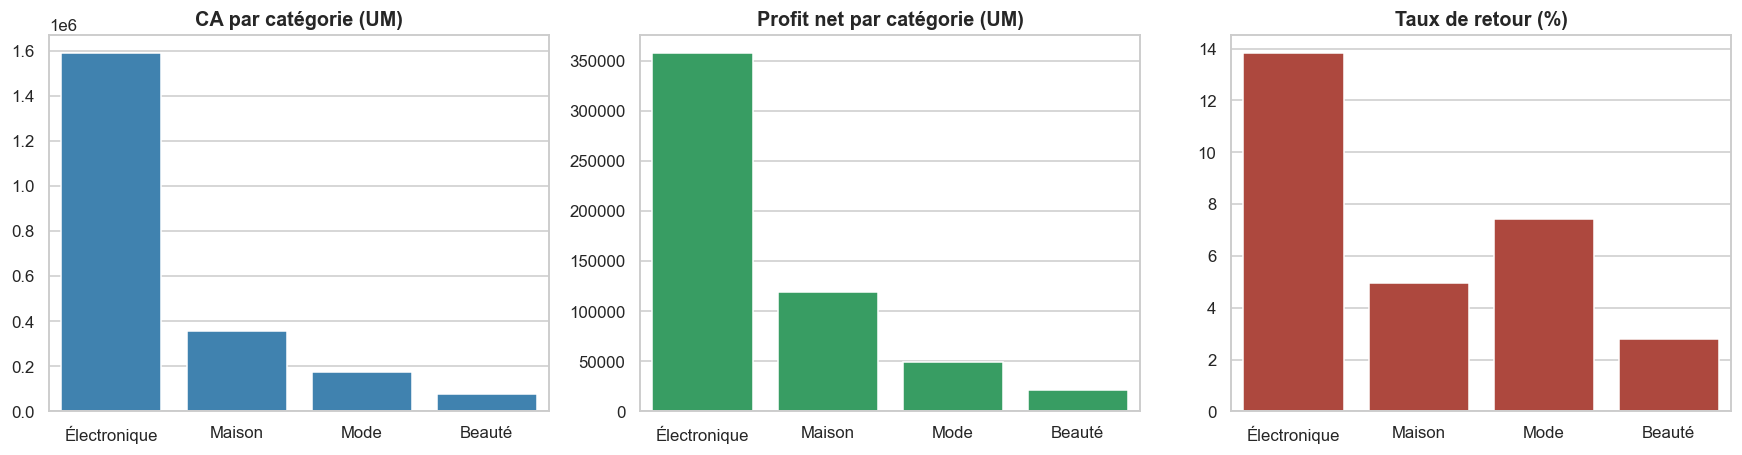

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
order = cat.index
sns.barplot(x=cat.index, y=cat.CA, order=order, ax=ax[0], color="#2e86c1"); ax[0].set_title("CA par catégorie (UM)")
sns.barplot(x=cat.index, y=cat.profit_net, order=order, ax=ax[1], color="#27ae60"); ax[1].set_title("Profit net par catégorie (UM)")
sns.barplot(x=cat.index, y=cat.taux_retour, order=order, ax=ax[2], color="#c0392b"); ax[2].set_title("Taux de retour (%)")
for a_ in ax: a_.set_xlabel(""); a_.set_ylabel("")
plt.tight_layout(); save("03_categories"); plt.show()

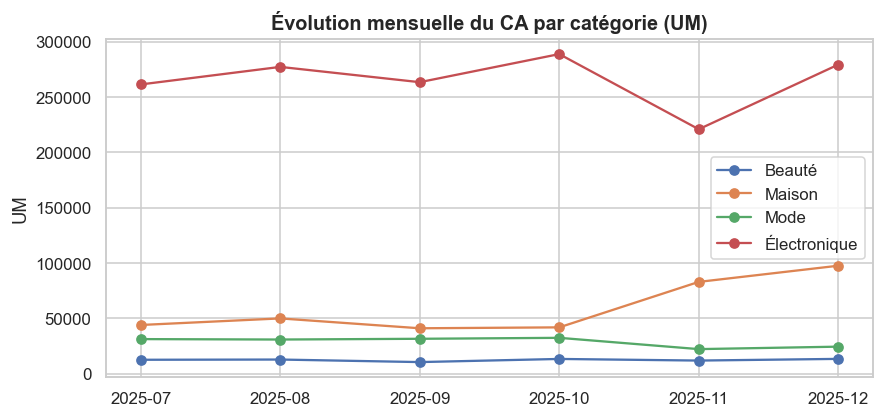

In [15]:
evo = df_clean.pivot_table(index="mois_label", columns="categorie", values="chiffre_affaires", aggfunc="sum")
px.line(evo, markers=True, title="Évolution mensuelle du CA par catégorie (UM)",
        labels={"value": "CA (UM)", "mois_label": "Mois", "categorie": "Catégorie"}).show()
fig, ax = plt.subplots(figsize=(9, 4)); evo.plot(marker="o", ax=ax)
ax.set_title("Évolution mensuelle du CA par catégorie (UM)"); ax.set_xlabel(""); ax.set_ylabel("UM"); ax.legend(title="")
save("04_evolution_categories"); plt.show()

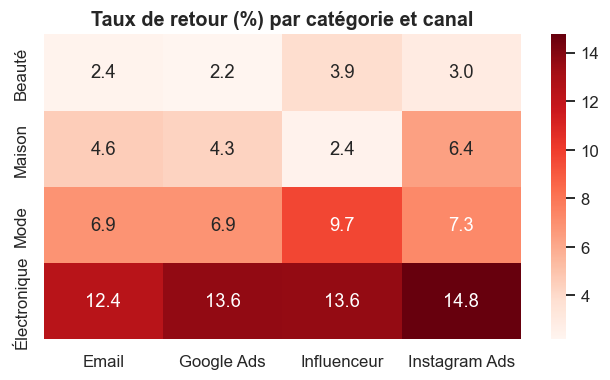

In [16]:
# Heatmap : taux de retour (%) par catégorie × canal — où se concentre le problème ?
hm = df_clean.pivot_table(index="categorie", columns="canal_marketing", values="indicateur_retour", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(7, 3.6)); sns.heatmap(hm, annot=True, fmt=".1f", cmap="Reds", ax=ax)
ax.set_title("Taux de retour (%) par catégorie et canal"); ax.set_xlabel(""); ax.set_ylabel("")
save("05_heatmap_retours"); plt.show()

**Réponse stratégique — quelle catégorie prioriser ou optimiser ?**
- **Électronique = moteur du groupe** : 72,4 % du CA et 65,4 % du profit net, avec 119 UM de profit par commande
  (contre 17 pour Mode et 12 pour Beauté). **À prioriser.**
- Mais l'Électronique détient aussi **le pire taux de retour : 13,8 %**, soit **284 296 UM de ventes perdues** ; **chaque point de retour évité ≈ 20 543 UM de CA**.
  C'est le levier d'optimisation le plus rentable de l'entreprise.
- **Maison** est la catégorie saine (retour 4,9 %, profit/commande 66 UM) : à développer en vente additionnelle.
- **Mode et Beauté** pèsent ensemble seulement 11,3 % du CA mais absorbent **49,1 % du budget marketing**
  (Beauté : 17,5 % du CA dépensé en marketing). **À optimiser** : rentabilité unitaire trop faible pour une acquisition coûteuse.

### 4.3 Analyse géographique

In [17]:
ville = df_clean.groupby("ville").agg(commandes=("id_commande", "count"), CA=("chiffre_affaires", "sum"),
        profit_net=("profit_net", "sum"), taux_annulation=("indicateur_annulation", "mean"),
        taux_retour=("indicateur_retour", "mean"))
ville[["taux_annulation", "taux_retour"]] *= 100
ville["profit_par_commande"] = ville.profit_net / ville.commandes
ville["part_du_CA_%"] = ville.CA / ville.CA.sum() * 100
pv = df_clean.pivot_table(index="ville", columns="mois_label", values="chiffre_affaires", aggfunc="sum")
ville["croissance_dec_vs_juil_%"] = (pv["2025-12"] / pv["2025-07"] - 1) * 100
ville = ville.sort_values("CA", ascending=False)
ville

,commandes,CA,profit_net,taux_annulation,taux_retour,profit_par_commande,part_du_CA_%,croissance_dec_vs_juil_%
ville,,,,,,,,
Kinshasa,2724,"664,685.11","166,193.50",0.26,8.00,61.01,30.26,17.57
Abidjan,1756,"437,373.33","108,365.75",0.00,8.71,61.71,19.91,22.24
Dakar,1346,"301,306.98","75,851.99",0.00,9.14,56.35,13.72,-8.48
Douala,1362,"292,258.85","71,827.21",12.92,7.20,52.74,13.30,74.46
Lomé,682,"165,886.23","41,579.85",0.00,6.60,60.97,7.55,16.75
Cotonou,631,"143,360.94","36,039.90",0.00,7.92,57.12,6.53,15.55
Libreville,467,"99,671.96","24,807.16",0.00,9.42,53.12,4.54,-33.07
Brazzaville,432,"92,087.78","22,718.23",0.00,7.87,52.59,4.19,53.53


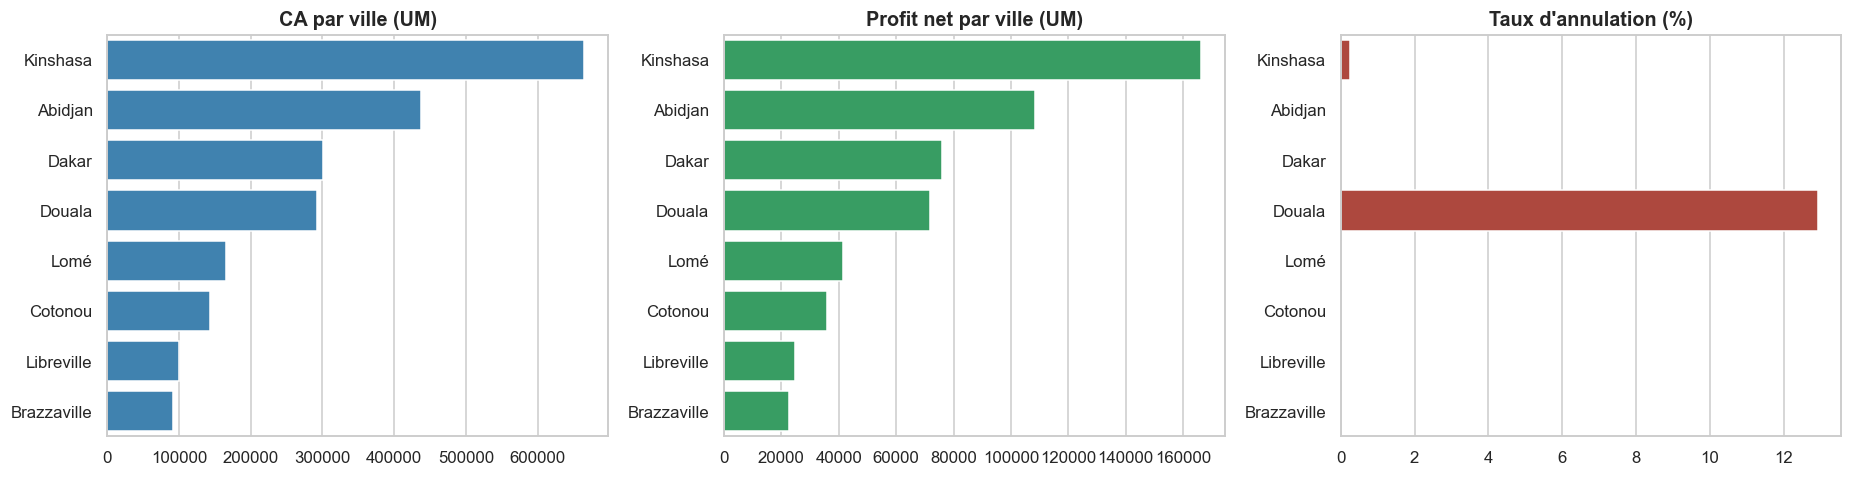

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.barplot(y=ville.index, x=ville.CA, ax=ax[0], color="#2e86c1"); ax[0].set_title("CA par ville (UM)")
sns.barplot(y=ville.index, x=ville.profit_net, ax=ax[1], color="#27ae60"); ax[1].set_title("Profit net par ville (UM)")
sns.barplot(y=ville.index, x=ville.taux_annulation, ax=ax[2], color="#c0392b"); ax[2].set_title("Taux d'annulation (%)")
for a_ in ax: a_.set_ylabel(""); a_.set_xlabel("")
plt.tight_layout(); save("06_villes"); plt.show()

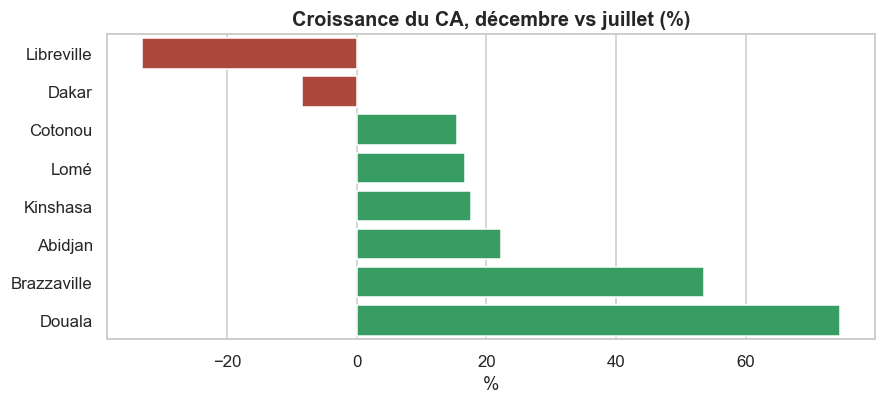

In [19]:
fig = px.line(pv.T, markers=True, title="Évolution mensuelle du CA par ville (UM)",
              labels={"value": "CA (UM)", "mois_label": "Mois", "ville": "Ville"}); fig.show()
fig, ax = plt.subplots(figsize=(9, 3.6)); croiss_ = ville["croissance_dec_vs_juil_%"].sort_values()
sns.barplot(y=croiss_.index, x=croiss_.values, ax=ax, palette=["#c0392b" if v < 0 else "#27ae60" for v in croiss_.values])
ax.set_title("Croissance du CA, décembre vs juillet (%)"); ax.set_xlabel("%"); ax.set_ylabel("")
save("07_croissance_villes"); plt.show()

In [20]:
# Focus Douala : l'annulation y est anormale (≈ 0 % partout ailleurs)
dd = df_clean[df_clean.ville == "Douala"]
print("Taux d'annulation Douala par mois (%) :")
print((dd.groupby("mois_label").indicateur_annulation.mean() * 100).round(1).to_string())
print("\nAnnulations hors Douala :", int(df_clean[df_clean.ville != "Douala"].indicateur_annulation.sum()), "sur",
      int((df_clean.ville != "Douala").sum()), "commandes")

Taux d'annulation Douala par mois (%) :
mois_label
2025-07   10.90
2025-08   15.10
2025-09   13.90
2025-10   11.40
2025-11   12.30
2025-12   13.80

Annulations hors Douala : 7 sur 8038 commandes


**Réponse stratégique — où investir ?**
- **Kinshasa et Abidjan** forment le cœur : 50,2 % du CA. Rentabilité unitaire élevée et stable : *investir pour consolider* (stock, livraison rapide).
- **Douala est la ville à plus forte croissance (+74 % entre juillet et décembre)**, mais **12,9 % de ses commandes sont annulées**,
  alors que **les autres villes sont proches de 0 %** : près de **47 691 UM de ventes** s'y perdent. L'anomalie est constante dans le temps,
  sur toutes les catégories et canaux : c'est un **problème opérationnel local** (livraison, confirmation, paiement), pas un problème de demande.
  → *Corriger d'abord, puis investir : Douala est le meilleur potentiel de croissance.*
- **Libreville (-33 %) et Dakar (-8 %)** reculent : pas d'investissement avant diagnostic.
- Les écarts de taux de retour entre villes sont faibles : le retour est un sujet **produit**, pas géographique.

### 4.4 Analyse marketing

**ROI = (Revenus − Coût marketing) / Coût marketing**, avec revenus = CA des commandes livrées attribuées au canal.

In [21]:
canal = df_clean.groupby("canal_marketing").agg(commandes=("id_commande", "count"), CA=("chiffre_affaires", "sum"),
        marge_brute=("marge_brute", "sum"), cout_marketing=("cout_marketing", "sum"), profit_net=("profit_net", "sum"))
canal["ROI (CA)"] = (canal.CA - canal.cout_marketing) / canal.cout_marketing
canal["ROI (marge brute)"] = (canal.marge_brute - canal.cout_marketing) / canal.cout_marketing
canal["coût_par_commande"] = canal.cout_marketing / canal.commandes
canal["part_budget_%"] = canal.cout_marketing / canal.cout_marketing.sum() * 100
canal["part_CA_%"] = canal.CA / canal.CA.sum() * 100

# Rétention par canal d'acquisition = % de clients ayant ≥ 2 commandes, selon le canal de leur 1ʳᵉ commande
prem = df_clean.sort_values("date_commande").drop_duplicates("id_client")[["id_client", "canal_marketing"]]
clients = df_clean.groupby("id_client").agg(nb_cmd=("id_commande", "count")).reset_index().merge(prem)
canal["taux_retention_%"] = clients.assign(rec=clients.nb_cmd > 1).groupby("canal_marketing").rec.mean() * 100
canal = canal.sort_values("ROI (CA)", ascending=False)
canal

,commandes,CA,marge_brute,cout_marketing,profit_net,ROI (CA),ROI (marge brute),coût_par_commande,part_budget_%,part_CA_%,taux_retention_%
canal_marketing,,,,,,,,,,,
Email,1894,"468,167.39","142,346.42","2,349.15","128,908.69",198.29,59.59,1.24,3.38,21.31,74.53
Google Ads,2393,"584,882.51","178,628.21","13,158.93","151,192.38",43.45,12.57,5.50,18.93,26.63,75.82
Instagram Ads,3765,"829,710.22","254,538.45","37,637.07","194,788.12",21.05,5.76,10.00,54.15,37.77,72.08
Influenceur,1348,"313,871.06","96,745.55","16,359.59","72,494.41",18.19,4.91,12.14,23.54,14.29,75.28


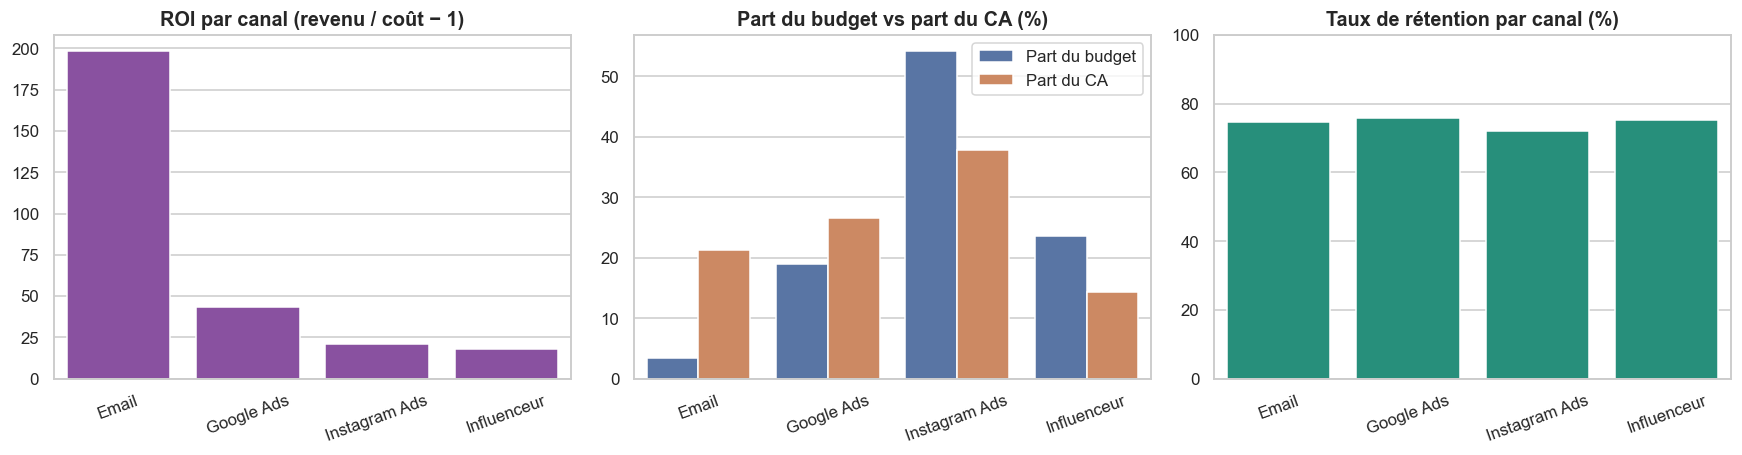

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
sns.barplot(x=canal.index, y=canal["ROI (CA)"], ax=ax[0], color="#8e44ad"); ax[0].set_title("ROI par canal (revenu / coût − 1)")
w = canal[["part_budget_%", "part_CA_%"]].rename(columns={"part_budget_%": "Part du budget", "part_CA_%": "Part du CA"}).reset_index().melt("canal_marketing")
sns.barplot(data=w, x="canal_marketing", y="value", hue="variable", ax=ax[1]); ax[1].set_title("Part du budget vs part du CA (%)"); ax[1].legend(title="")
sns.barplot(x=canal.index, y=canal["taux_retention_%"], ax=ax[2], color="#16a085"); ax[2].set_title("Taux de rétention par canal (%)"); ax[2].set_ylim(0, 100)
for a_ in ax: a_.set_xlabel(""); a_.set_ylabel(""); a_.tick_params(axis="x", rotation=20)
plt.tight_layout(); save("08_marketing"); plt.show()

In [23]:
px.scatter(canal.reset_index(), x="cout_marketing", y="CA", size="commandes", color="canal_marketing",
           title="Budget marketing vs CA généré (taille = nombre de commandes)",
           labels={"cout_marketing": "Coût marketing (UM)", "CA": "CA (UM)"}).show()

**Réponse stratégique — quel canal financer, lequel réduire ?**
- **Email : ROI de 198** pour un coût de 1,2 UM par commande : le canal le plus rentable de très loin, mais sous-exploité
  (3,4 % du budget pour 21,3 % du CA). **À développer** (CRM, relance, programme de fidélité).
- **Google Ads : ROI de 43**, équilibre efficace entre volume et coût. **À augmenter progressivement.**
- **Instagram Ads (ROI 21) et Influenceurs (ROI 18)** absorbent **77,7 % du budget pour 52,1 % du CA**.
  Les Influenceurs coûtent 12,1 UM par commande, soit ~10× l'Email. **À optimiser / réduire** (tester cible et créatifs, plafonner les cachets).
- **La rétention est quasi identique d'un canal à l'autre (72–76 %)** : le canal d'acquisition ne fait pas la fidélité ; c'est le suivi après la 1ʳᵉ commande qui compte.
- *Limite* : le coût marketing du dataset est de l'ordre de quelques UM par commande ; le ROI sur le CA est donc très élevé partout. Le **classement** des canaux est fiable, pas la valeur absolue du ROI (à confirmer avec les budgets réels).

### 4.5 Analyse clients

In [24]:
cl = df_clean.groupby("id_client").agg(nb_commandes=("id_commande", "count"), CA=("chiffre_affaires", "sum"),
        profit=("profit_net", "sum"), premiere_commande=("date_commande", "min"), derniere_commande=("date_commande", "max")).reset_index()
print(f"Clients uniques : {len(cl):,}".replace(",", " "))
print(f"Clients récurrents (≥ 2 commandes) : {(cl.nb_commandes > 1).mean() * 100:.1f} %")
print(f"Commandes par client : médiane {cl.nb_commandes.median():.0f}, moyenne {cl.nb_commandes.mean():.1f}, max {cl.nb_commandes.max()}")

Clients uniques : 1 747
Clients récurrents (≥ 2 commandes) : 74.0 %
Commandes par client : médiane 2, moyenne 5.4, max 29


536 clients (30.7 %) génèrent 80 % du CA ; les 20 % meilleurs clients génèrent 65.4 % du CA.


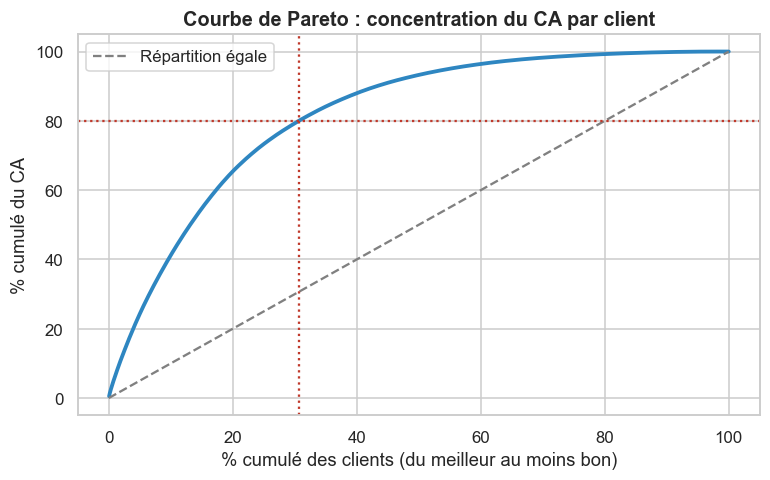

In [25]:
# Pareto : quelle part des clients génère 80 % du CA ?
p = cl.sort_values("CA", ascending=False).reset_index(drop=True)
p["part_cum_clients"] = (p.index + 1) / len(p) * 100
p["part_cum_CA"] = p.CA.cumsum() / p.CA.sum() * 100
n80 = int((p.part_cum_CA <= 80).sum() + 1)
top20 = p.loc[int(len(p) * .2) - 1, "part_cum_CA"]
print(f"{n80} clients ({n80 / len(p) * 100:.1f} %) génèrent 80 % du CA ; les 20 % meilleurs clients génèrent {top20:.1f} % du CA.")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(p.part_cum_clients, p.part_cum_CA, color="#2e86c1", lw=2.5)
ax.plot([0, 100], [0, 100], ls="--", color="grey", label="Répartition égale")
ax.axhline(80, color="#c0392b", ls=":"); ax.axvline(n80 / len(p) * 100, color="#c0392b", ls=":")
ax.set_title("Courbe de Pareto : concentration du CA par client"); ax.set_xlabel("% cumulé des clients (du meilleur au moins bon)")
ax.set_ylabel("% cumulé du CA"); ax.legend(); save("09_pareto"); plt.show()

In [26]:
# Top 10 clients
cl.sort_values("CA", ascending=False).head(10)[["id_client", "nb_commandes", "CA", "profit"]].reset_index(drop=True)

,id_client,nb_commandes,CA,profit
0,C0157,26,"11,401.06","2,772.70"
1,C0266,19,"10,753.74","2,532.18"
2,C0051,17,"9,079.95","2,145.71"
3,C0114,21,"8,874.68","2,132.33"
4,C0379,25,"7,948.45","1,972.76"
5,C0352,14,"7,594.56","1,855.96"
6,C0184,20,"7,540.09","1,786.01"
7,C0364,19,"7,538.23","1,841.41"
8,C0082,23,"7,465.21","1,848.19"
9,C0273,23,"7,168.99","1,774.64"


,clients,CA,profit,% clients,% CA,CA_par_client
segment,,,,,,
Occasionnel (1),454,"97,415.45","24,843.06",25.99,4.43,214.57
Régulier (2-3),685,"361,383.78","91,169.81",39.21,16.45,527.57
Fidèle (4-7),207,"238,304.79","58,381.43",11.85,10.85,"1,151.23"
VIP (8+),401,"1,499,527.16","372,989.30",22.95,68.26,"3,739.47"


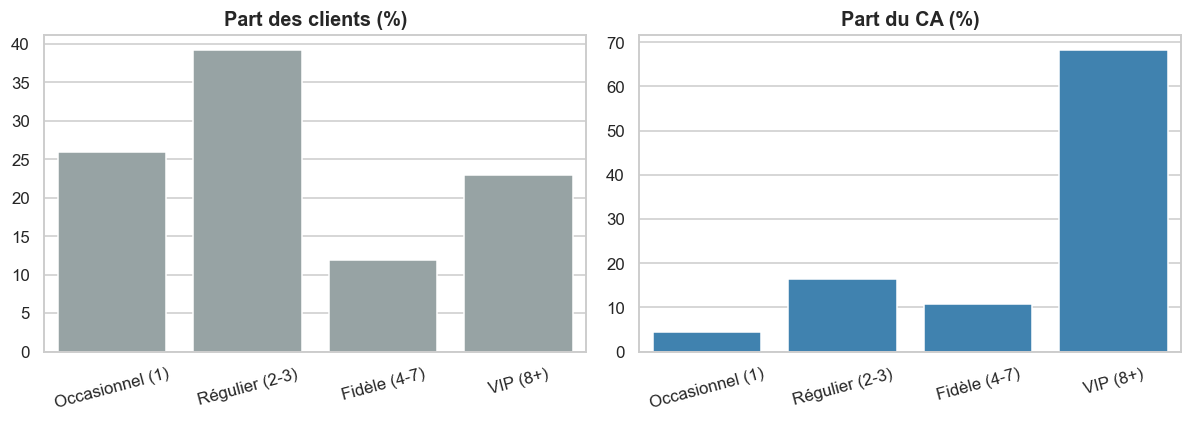

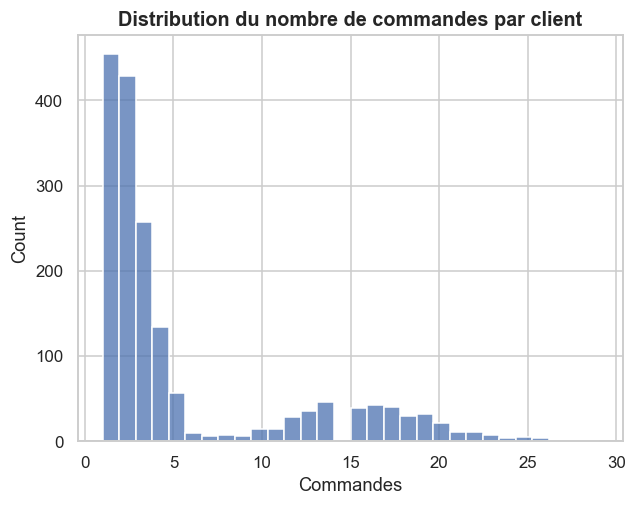

In [27]:
# Segmentation simple selon la fréquence d'achat
cl["segment"] = pd.cut(cl.nb_commandes, [0, 1, 3, 7, 1000], labels=["Occasionnel (1)", "Régulier (2-3)", "Fidèle (4-7)", "VIP (8+)"])
seg = cl.groupby("segment", observed=True).agg(clients=("id_client", "count"), CA=("CA", "sum"), profit=("profit", "sum"))
seg["% clients"] = seg.clients / seg.clients.sum() * 100
seg["% CA"] = seg.CA / seg.CA.sum() * 100
seg["CA_par_client"] = seg.CA / seg.clients
display(seg)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=seg.index, y=seg["% clients"], ax=ax[0], color="#95a5a6"); ax[0].set_title("Part des clients (%)")
sns.barplot(x=seg.index, y=seg["% CA"], ax=ax[1], color="#2e86c1"); ax[1].set_title("Part du CA (%)")
for a_ in ax: a_.set_xlabel(""); a_.set_ylabel(""); a_.tick_params(axis="x", rotation=15)
plt.tight_layout(); save("10_segments"); plt.show()
sns.histplot(cl.nb_commandes, bins=30); plt.title("Distribution du nombre de commandes par client"); plt.xlabel("Commandes"); plt.show()

**Réponse stratégique — comment améliorer la rétention ?**
- **1 747 clients**, dont **74,0 % récurrents** : la base est déjà fidèle, mais très concentrée. **536 clients (30,7 %)** génèrent 80 % du CA
  et les 20 % meilleurs en génèrent 65,4 % (écart au 80/20 théorique : la concentration est plus modérée, mais réelle).
- Les **VIP (8 commandes ou plus)** représentent 23,0 % des clients mais **68,3 % du CA** : les perdre coûterait très cher.
- Les **occasionnels (1 seule commande) sont 26,0 % des clients pour 4,4 % du CA** : c'est le réservoir de croissance à convertir en 2ᵉ achat.
- **Actions** : (1) programme VIP avec avantage dédié et service prioritaire ; (2) séquence email de relance à J+15/J+30 après la 1ʳᵉ commande ;
  (3) offre de 2ᵉ achat ciblée sur Maison / Électronique (catégories à forte valeur) ; (4) alerte « client à risque » pour les clients fidèles inactifs.

## 5. Cinq recommandations stratégiques

| # | Recommandation | Pourquoi (chiffres) | Impact attendu |
|---|---|---|---|
| **1** | **Réduire le taux de retour de l'Électronique** (fiches produit et photos fiables, contrôle qualité avant expédition, analyse des 10 produits les plus retournés) | 13,8 % de retours vs 4,9 % (Maison) ; 284 296 UM de ventes perdues | ≈ **20 543 UM de CA par point de retour évité** ; passer de 13,8 % à 10 % ≈ 78 865 UM |
| **2** | **Réallouer le budget marketing** : réduire Influenceurs/Instagram de 20 %, doubler l'effort Email, renforcer Google Ads | Email ROI 198, Google 43, Instagram 21, Influenceur 18 ; 77,7 % du budget pour 52,1 % du CA | ≈ 10 799 UM redéployables vers les canaux à plus fort rendement |
| **3** | **Résoudre l'anomalie d'annulation de Douala, puis y investir** | 12,9 % d'annulations vs ≈ 0 % ailleurs ; croissance +74 % sur 6 mois | ≈ **47 691 UM de CA récupérables** dans la ville au plus fort potentiel |
| **4** | **Lancer un programme de fidélisation par segment** (VIP, relance du 2ᵉ achat, email automatisé) | VIP : 23,0 % des clients, 68,3 % du CA ; 26,0 % de clients occasionnels | Protéger le cœur de CA et convertir les occasionnels en récurrents |
| **5** | **Optimiser Mode et Beauté** : marketing plafonné, ventes croisées avec Électronique/Maison, hausse du panier, revue des remises | Profit/commande 17 (Mode) et 12 (Beauté) vs 119 (Électronique) ; 49,1 % du budget marketing | Améliorer la rentabilité sans perdre de volume stratégique |

## 6. Conclusion business orientée action

AfriMarket est **rentable (547 384 UM de profit net estimé, 24,9 % de marge nette)**, porté par l'Électronique, par Kinshasa et Abidjan,
et par une base de clients très fidèle. Les pertes ne viennent pas d'un manque de demande mais de **trois fuites identifiables** :
les **retours d'Électronique**, l'**annulation anormale à Douala** et un **budget marketing mal réparti** (77,7 % du budget sur les deux canaux au plus faible ROI).

**Plan d'action**
- **30 jours** : enquête terrain sur Douala (livraison, confirmation, paiement) ; audit des 10 produits électroniques les plus retournés ; gel des hausses de budget Influenceurs/Instagram.
- **60 jours** : redéploiement de 20 % du budget Influenceurs/Instagram vers Email et Google Ads ; lancement des séquences email de relance et du statut VIP.
- **90 jours** : mesurer l'effet (taux de retour Électronique, annulation Douala, ROI par canal, % de 2ᵉ achats) ; si Douala est stabilisée, en faire la ville d'investissement n°1.

**Indicateurs de pilotage** : taux de retour par catégorie, annulation par ville, ROI par canal, taux de 2ᵉ achat, profit par commande.

*Limites :* marge estimée par hypothèse de coût d'achat (à remplacer par les coûts réels) ; période de 6 mois seulement (saisonnalité annuelle non observable) ;
coûts marketing de faible niveau absolu (classement des canaux fiable, ROI absolu à confirmer).